# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [17]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)

# ---- shared style helpers (used by every question) ----
ACCENT, GREY = '#E69F00', '#B5B5B5'                       # Okabe-Ito orange + neutral grey (CVD-safe)
CONT_COLORS = {'Africa': '#E07B39', 'Asia': '#2A6F97', 'Europe': '#8E5C9E',
               'North America': '#2A9D8F', 'South America': '#E9C46A', 'Oceania': '#8D99AE'}

def insight_title(headline, sub=None):
    """Two-line, left-aligned insight title so long findings never run off the figure."""
    t = f"<b>{headline}</b>" + (f"<br><span style='font-size:14px;color:#555'>{sub}</span>" if sub else "")
    return dict(text=t, x=0, xanchor='left', y=0.96, yanchor='top')

(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

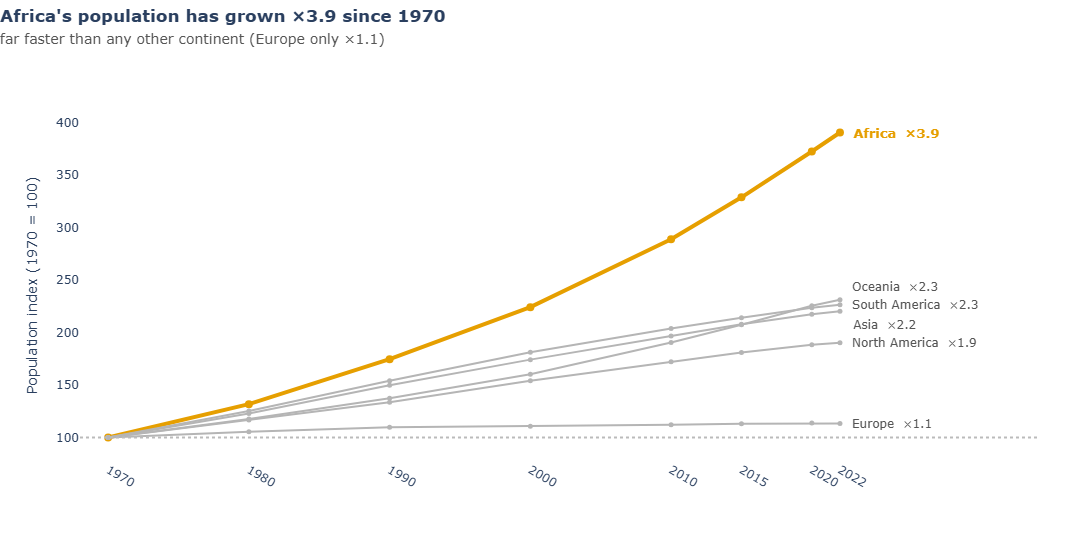

In [6]:
# Q1
# YOUR CODE HERE
# Q1 — line chart, indexed to 1970 = 100
cont = df_long.groupby(['Continent', 'Year'], as_index=False)['Population'].sum()
base = cont[cont['Year'] == 1970].set_index('Continent')['Population']
cont['Index'] = cont['Population'] / cont['Continent'].map(base) * 100

last = cont[cont['Year'] == 2022].set_index('Continent')['Index']
top = last.idxmax()      # fastest-growing continent, derived from data
slow = last.idxmin()     # slowest-growing continent

fig = px.line(
    cont, x='Year', y='Index', color='Continent', markers=True,
    color_discrete_map={c: (ACCENT if c == top else GREY) for c in cont['Continent'].unique()},
    template='plotly_white',
)
fig.for_each_trace(lambda t: t.update(line_width=4 if t.name == top else 2,
                                      marker_size=8 if t.name == top else 5))

nudge = {'Oceania': 13, 'South America': 0, 'Asia': -13}          # keeps the three close labels apart
for c, v in last.items():
    fig.add_annotation(x=2022, y=v, xanchor='left', xshift=10, yshift=nudge.get(c, 0), showarrow=False,
                       text=f"<b>{c}  ×{v/100:.1f}</b>" if c == top else f"{c}  ×{v/100:.1f}",
                       font=dict(color=ACCENT if c == top else '#555', size=13 if c == top else 12))

fig.add_hline(y=100, line_dash='dot', line_color='#BBBBBB')       # 1970 baseline
fig.update_layout(title=insight_title(f"{top}'s population has grown ×{last[top]/100:.1f} since 1970",
                                      f"far faster than any other continent ({slow} only ×{last[slow]/100:.1f})"),
                  showlegend=False, margin=dict(t=110, r=40), height=540,
                  yaxis_title='Population index (1970 = 100)', xaxis_title=None)
fig.update_xaxes(showgrid=False, range=[1968, 2036], tickvals=sorted(cont['Year'].unique()))
fig.update_yaxes(showgrid=False)
fig.show()

---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

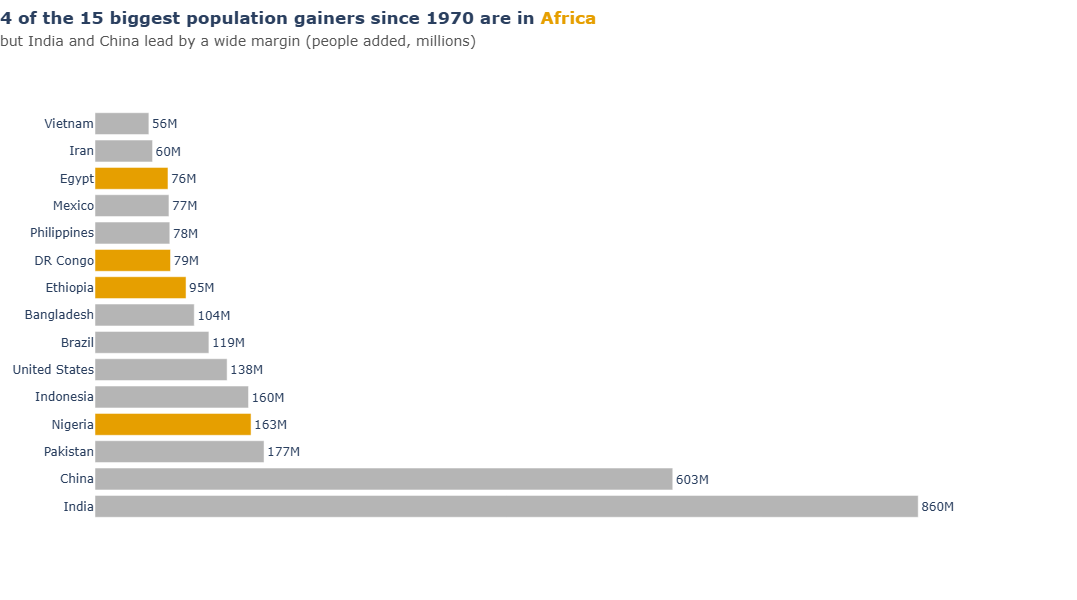

In [8]:
# Q2
# YOUR CODE HERE
# Q2 — sorted bar chart: top-15 population gains 1970 → 2022
d = df_long.assign(Added=(df['2022 Population'] - df['1970 Population']) / 1e6)
top15 = d.nlargest(15, 'Added').sort_values('Added')               # ascending → largest bar on top
top15['Group'] = np.where(top15['Continent'] == 'Africa', 'Africa', 'Other continents')
n_africa = int((top15['Continent'] == 'Africa').sum())

fig = px.bar(top15, x='Added', y='Country', orientation='h', color='Group', text='Added',
             color_discrete_map={'Africa': ACCENT, 'Other continents': GREY},
             category_orders={'Country': top15['Country'].tolist()}, template='plotly_white')
fig.update_traces(texttemplate='%{x:,.0f}M', textposition='outside', cliponaxis=False)
fig.update_layout(title=insight_title(f"{n_africa} of the 15 biggest population gainers since 1970 are in "
                                      f"<span style='color:{ACCENT}'>Africa</span>",
                                      "but India and China lead by a wide margin (people added, millions)"),
                  showlegend=False, yaxis_title=None, height=600, margin=dict(t=110, r=60))
fig.update_xaxes(visible=False, range=[0, top15['Added'].max() * 1.12])
fig.update_yaxes(showgrid=False)
fig.show()


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

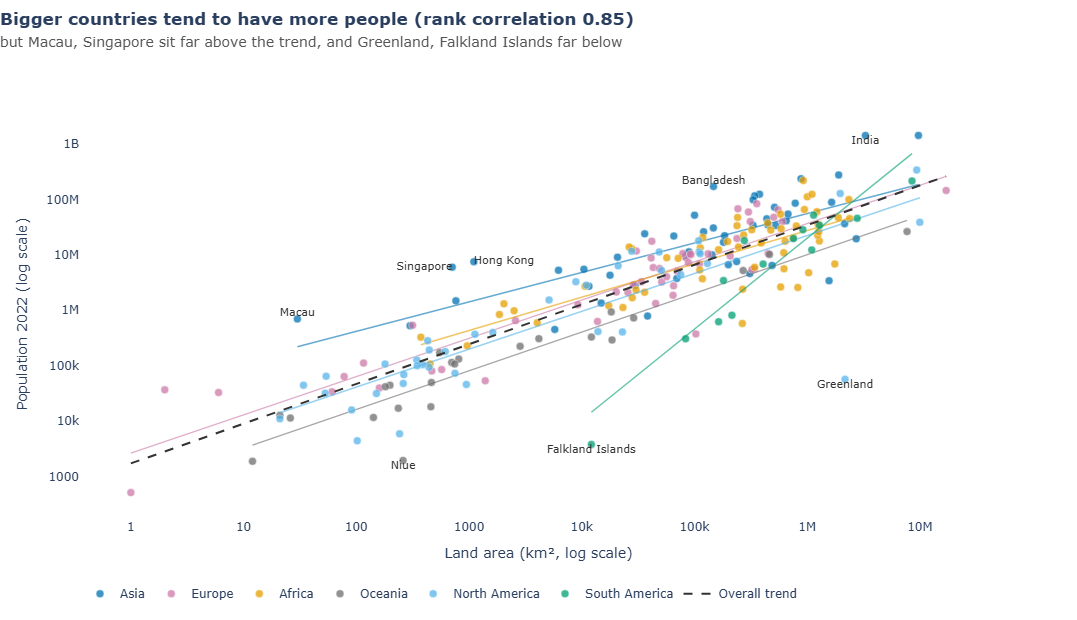

In [9]:
# Q3
# YOUR CODE HERE
# Q3 — scatter plot, log-log, per-continent trend lines, outliers labelled
d = df.copy()
d['logA'], d['logP'] = np.log10(d['Area']), np.log10(d['2022 Population'])
slope, intercept = np.polyfit(d['logA'], d['logP'], 1)
d['resid'] = d['logP'] - (slope * d['logA'] + intercept)
rho = d['Area'].corr(d['2022 Population'], method='spearman')

hi = ', '.join(d.nlargest(2, 'resid')['Country'])      # furthest above the trend
lo = ', '.join(d.nsmallest(2, 'resid')['Country'])     # furthest below the trend

fig = px.scatter(d, x='Area', y='2022 Population', color='Continent', hover_name='Country',
                 log_x=True, log_y=True, color_discrete_map=CONT_COLORS, opacity=0.75,
                 trendline='ols', trendline_options=dict(log_x=True, log_y=True), template='plotly_white')
fig.update_traces(selector=dict(mode='markers'), marker=dict(size=8, line=dict(width=0.5, color='white')))
fig.update_traces(selector=dict(mode='lines'), line=dict(width=1.5), opacity=0.6)   # per-continent trends
for t in fig.data:                                   # keep one legend entry per continent
    if t.mode == 'lines': t.showlegend = False

# overall trend (dashed)
xs = np.array([d['Area'].min(), d['Area'].max()])
fig.add_scatter(x=xs, y=10 ** (intercept + slope * np.log10(xs)), mode='lines',
                line=dict(color='#333333', dash='dash', width=2), name='Overall trend', hoverinfo='skip')

# label the biggest outliers (log-residuals) + India, the largest in absolute terms
out = pd.concat([d.nlargest(4, 'resid'), d.nsmallest(3, 'resid'), d[d['Country'] == 'India']]).drop_duplicates('Country')
pos = {'Macau': 'top center', 'Singapore': 'middle left', 'Hong Kong': 'middle right', 'Bangladesh': 'top center',
       'India': 'bottom center', 'Greenland': 'bottom center', 'Falkland Islands': 'bottom center', 'Niue': 'bottom center'}
fig.add_scatter(x=out['Area'], y=out['2022 Population'], mode='text', text=out['Country'],
                textposition=[pos.get(c, 'top center') for c in out['Country']],
                textfont=dict(size=11, color='#333'), showlegend=False, hoverinfo='skip')

fig.update_layout(title=insight_title(f"Bigger countries tend to have more people (rank correlation {rho:.2f})",
                                      f"but {hi} sit far above the trend, and {lo} far below"),
                  height=620, margin=dict(t=110), xaxis_title='Land area (km², log scale)',
                  yaxis_title='Population 2022 (log scale)', legend_title_text=None,
                  legend=dict(orientation='h', y=-0.15, x=0))
fig.update_xaxes(showgrid=False); fig.update_yaxes(showgrid=False)
fig.show()

---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

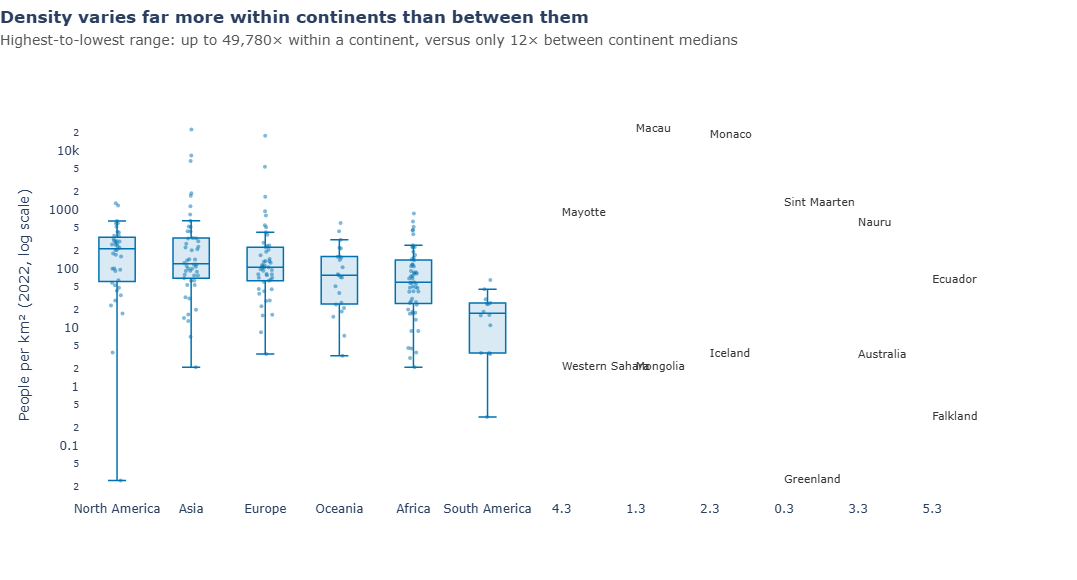

In [10]:
# Q4
# YOUR CODE HERE
# Q4 — box plot of population density by continent (log scale), with all countries as points
med = df.groupby('Continent')['Density'].median().sort_values(ascending=False)
order = med.tolist() and med.index.tolist()
rng = df.groupby('Continent')['Density'].agg(lambda s: s.max() / s.min())

fig = px.box(df, x='Continent', y='Density', points='all', hover_name='Country', log_y=True,
             category_orders={'Continent': order}, color_discrete_sequence=['#0072B2'], template='plotly_white')
fig.update_traces(marker=dict(size=4, opacity=0.5), fillcolor='rgba(0,114,178,0.15)',
                  line=dict(width=1.5), jitter=0.4, pointpos=0)

# labels for the densest / sparsest country per continent, placed beside each box (x as category index)
ext = pd.concat([df.loc[df.groupby('Continent')['Density'].idxmax()],
                 df.loc[df.groupby('Continent')['Density'].idxmin()]])
fig.add_scatter(x=[order.index(c) + 0.3 for c in ext['Continent']], y=ext['Density'], mode='text',
                text=ext['Country'], textposition='middle right', textfont=dict(size=11, color='#333'),
                showlegend=False, hoverinfo='skip')

fig.update_layout(title=insight_title(f"Density varies far more within continents than between them",
                                      f"Highest-to-lowest range: up to {rng.max():,.0f}× within a continent, "
                                      f"versus only {med.max()/med.min():.0f}× between continent medians"),
                  showlegend=False, height=580, margin=dict(t=110, r=100), xaxis_title=None,
                  yaxis_title='People per km² (2022, log scale)')
fig.update_xaxes(showgrid=False); fig.update_yaxes(showgrid=False)
fig.show()

---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

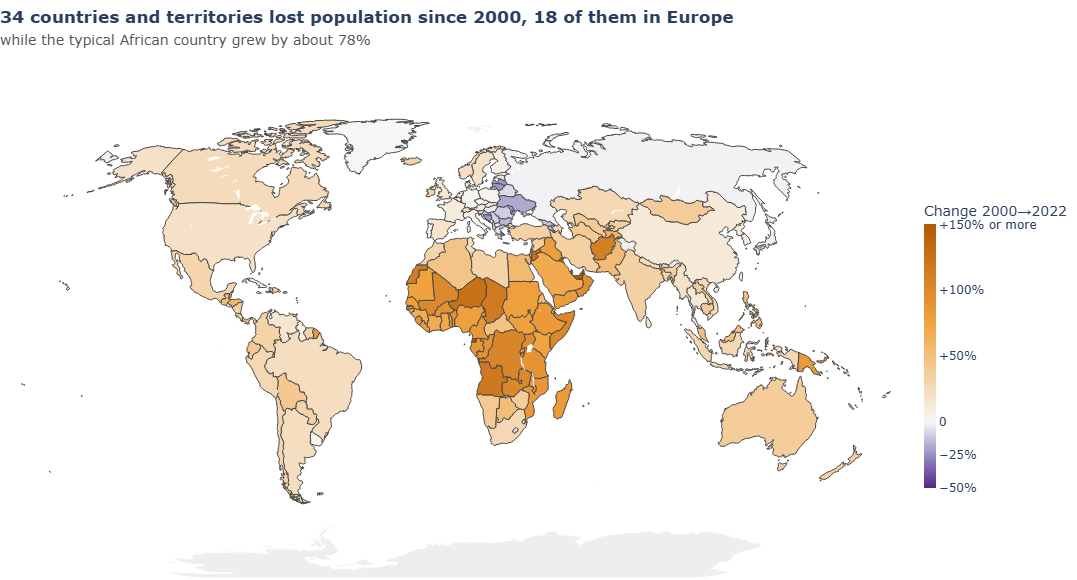

In [11]:
# Q5
# YOUR CODE HERE
# Q5 — choropleth of % population change 2000 → 2022 (diverging, centred on 0)
d = df.assign(Change=(df['2022 Population'] / df['2000 Population'] - 1) * 100)
n_shrank = int((d['Change'] < 0).sum())
n_eu = int(((d['Change'] < 0) & (d['Continent'] == 'Europe')).sum())
afr_med = d.loc[d['Continent'] == 'Africa', 'Change'].median()

lo, hi = -50, 150
zero = (0 - lo) / (hi - lo)
scale = [[0, '#542788'], [zero / 2, '#998EC3'], [zero, '#F7F7F7'],
         [zero + (1 - zero) / 2, '#F1A340'], [1, '#B35806']]

fig = px.choropleth(d, locations='CCA3', color='Change', hover_name='Country',
                    hover_data={'CCA3': False, 'Change': ':.1f'}, range_color=[lo, hi],
                    color_continuous_scale=scale, projection='natural earth', template='plotly_white')
fig.update_geos(showframe=False, showcoastlines=False, showland=True, landcolor='#EEEEEE',
                showcountries=True, countrycolor='white')
fig.update_coloraxes(colorbar=dict(title='Change 2000→2022', thickness=12, len=0.65,
                                   tickvals=[-50, -25, 0, 50, 100, 150],
                                   ticktext=['−50%', '−25%', '0', '+50%', '+100%', '+150% or more']))
fig.update_layout(title=insight_title(f"{n_shrank} countries and territories lost population since 2000, {n_eu} of them in Europe",
                                      f"while the typical African country grew by about {afr_med:.0f}%"),
                  height=580, margin=dict(l=0, r=0, t=110, b=0))
fig.show()

---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

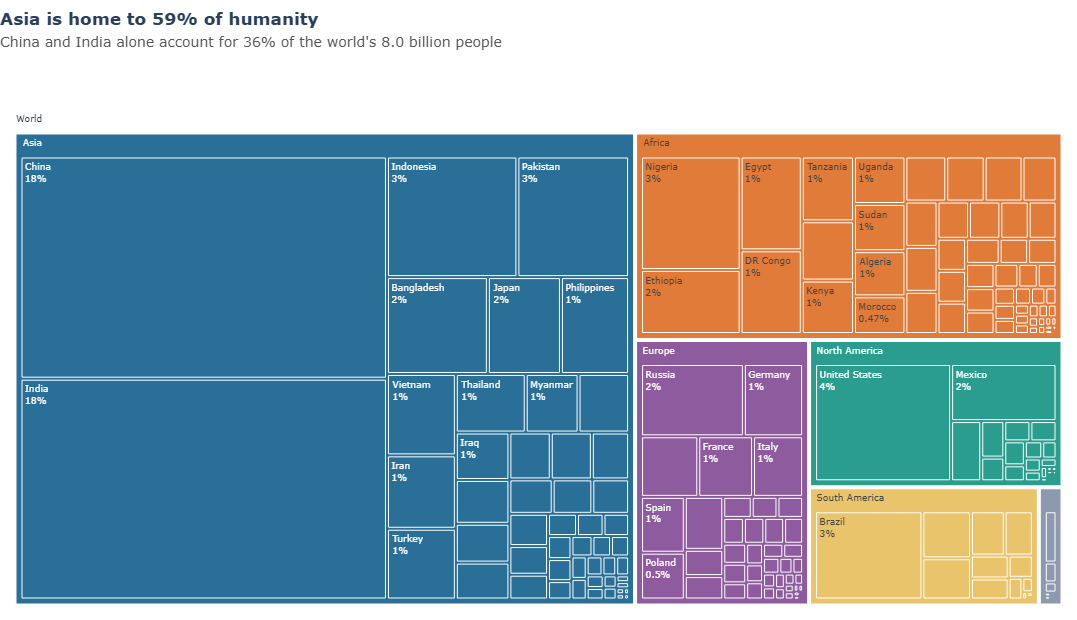

In [18]:
# Q6
# YOUR CODE HERE
# Q6 — treemap: World → continent → country, area = 2022 population
total = df['2022 Population'].sum()
asia_share = df.loc[df['Continent'] == 'Asia', '2022 Population'].sum() / total * 100
top2 = df.nlargest(2, '2022 Population')
top2_share = top2['2022 Population'].sum() / total * 100
top2_names = ' and '.join(top2['Country'])

fig = px.treemap(df, path=[px.Constant('World'), 'Continent', 'Country'], values='2022 Population',
                 color='Continent', color_discrete_map={**CONT_COLORS, '(?)': '#FFFFFF'}, template='plotly_white')
fig.update_traces(textinfo='label+percent root', marker_line=dict(width=1, color='white'),
                  hovertemplate='<b>%{label}</b><br>Population: %{value:,.0f}<br>Share of world: %{percentRoot:.1%}<extra></extra>')
fig.update_layout(title=insight_title(f"Asia is home to {asia_share:.0f}% of humanity",
                                      f"{top2_names} alone account for {top2_share:.0f}% of the world's {total/1e9:.1f} billion people"),
                  height=620, margin=dict(l=10, r=10, t=110, b=10), uniformtext=dict(minsize=9, mode='hide'))
fig.show()

---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE*

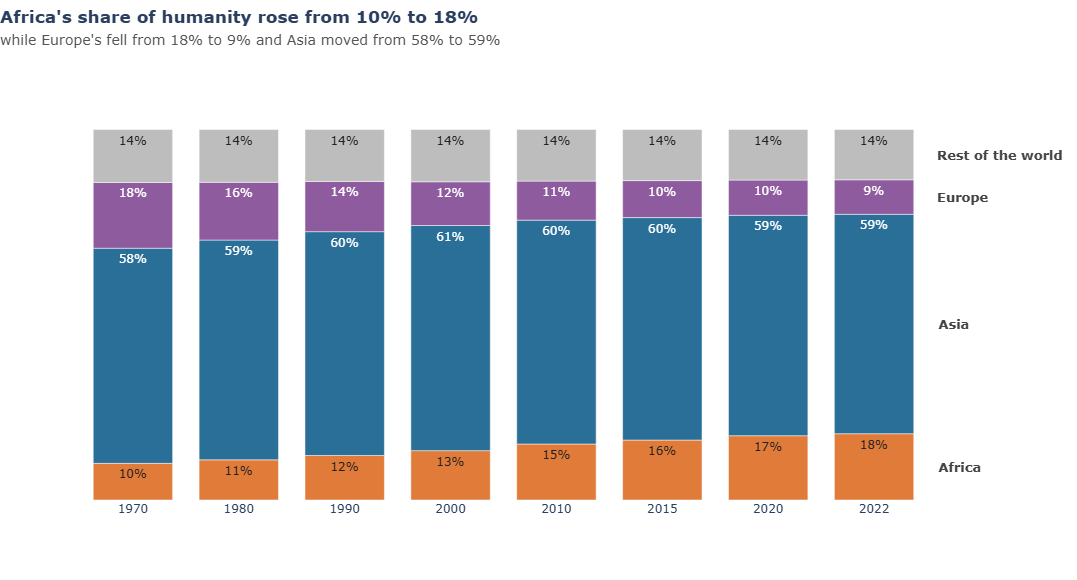

In [19]:
# Q7
# YOUR CODE HERE
# Q7 — 100% stacked bar: share of world population, 1970–2022
COLORS = {'Africa': '#E07B39', 'Asia': '#2A6F97', 'Europe': '#8E5C9E', 'Rest of the world': '#BDBDBD'}
order = ['Africa', 'Asia', 'Europe', 'Rest of the world']          # bottom → top

g = df_long.assign(Group=np.where(df_long['Continent'].isin(['Africa', 'Asia', 'Europe']),
                                  df_long['Continent'], 'Rest of the world'))
s = g.groupby(['Year', 'Group'], as_index=False)['Population'].sum()
s['Share'] = s['Population'] / s.groupby('Year')['Population'].transform('sum') * 100
s['Year'] = s['Year'].astype(str)
sh = s.pivot(index='Year', columns='Group', values='Share')

fig = px.bar(s, x='Year', y='Share', color='Group', text='Share', color_discrete_map=COLORS,
             category_orders={'Group': order, 'Year': sorted(s['Year'].unique())}, template='plotly_white')
fig.update_traces(texttemplate='%{y:.0f}%', textposition='inside', textfont_size=12)
fig.for_each_trace(lambda t: t.update(textfont_color='white' if t.name == 'Asia' else '#222'))
fig.for_each_trace(lambda t: t.update(textfont_color='white' if t.name in ('Asia', 'Europe') else '#222'))
cum = 0                                                         
for grp in order:
    v = sh.loc['2022', grp]
    fig.add_annotation(x=1.01, xref='paper', y=cum + v / 2, yref='y', xanchor='left', showarrow=False,
                       text=f"<b>{grp}</b>", font=dict(color='#444', size=13))
    cum += v

fig.update_layout(title=insight_title(f"Africa's share of humanity rose from {sh.loc['1970','Africa']:.0f}% to {sh.loc['2022','Africa']:.0f}%",
                                      f"while Europe's fell from {sh.loc['1970','Europe']:.0f}% to {sh.loc['2022','Europe']:.0f}% "
                                      f"and Asia moved from {sh.loc['1970','Asia']:.0f}% to {sh.loc['2022','Asia']:.0f}%"),
                  showlegend=False, height=580, bargap=0.25, margin=dict(t=110, r=150),
                  xaxis_title=None, yaxis_title=None)
fig.update_yaxes(visible=False); fig.update_xaxes(showgrid=False)
fig.show()

In [16]:
color_discrete_map={**CONT_COLORS, '(?)': '#FFFFFF'}
